# Indicadores de trayectoria: abandono en el nivel secundario, 2010-11 a 2023-24

Fuente: https://datos.estadistica.ec.gba.gov.ar/dataset/tasa-de-abandono-del-nivel-secundario-por-municipio-provincia-de-buenos-aires-anos-2010-11-a-2023-24

Estructura: 0. Alcance y configuración · 1. Calidad de datos · 2. Evolución provincial · 3. Municipios · 4. Regiones · 5. Cruce con la serie de matrícula (02) · 6. Cruce con la expansión (03) · 7. Cruce con el padrón (01) · 8. Casos para el informe de síntesis · 9. Control de cifras citadas.

<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-alcance -->
> ### ⚠️ Alcance de este notebook
> - **Archivo**: `11_tasa_de_abandono_del_nivel_secundario.xlsx` (Dirección Provincial de Estadística), con 14 ciclos (2010-11 a 2023-24) para 135 municipios, más el total provincial.
> - **Qué mide**: la tasa de abandono interanual del nivel secundario, en %. Es un **residuo**: 100 menos las tasas de repitencia, reinscripción y promoción efectiva. No sigue a una cohorte ni cuenta alumnos, y **puede dar negativa** cuando un municipio recibe más alumnos de los que pierde.
> - **Ciclo**: "2015-16" es el pasaje del ciclo lectivo 2015 al 2016. Para cruzar con otras fuentes se usa el **año de inicio** (2015), que es el año de la matrícula base.
> - **Cruce por código**: `municipio_id` = "06" + código de 3 dígitos, el mismo id del padrón y de la expansión. El nombre canónico sale del padrón.
> - **Ciclo 2020-21 atípico** (pandemia, promoción acompañada): se muestra, se marca y las comparaciones se reportan con y sin él.
> - **Otras fuentes que usa**: padrón (01), serie municipal 2015–2025 (02) y expansión (03). La marca de verificación lleva el hash de los cuatro archivos.

## 0. Configuración

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import TwoSlopeNorm

sys.path.insert(0, str(Path("..").resolve() / "src"))
import utils as u

u.aplicar_estilo()

# True: la celda de control (sección 9) falla si una cifra citada no coincide.
MODO_ESTRICTO = True

HASH_DATOS = u.hash_por_archivo({
    "aband": u.ARCHIVO_ABANDONO,
    "padron": u.ARCHIVO_ESTABLECIMIENTOS,
    "serie": u.ARCHIVO_MATRICULA_MUNICIPIOS,
    "exp": u.ARCHIVO_EXPANSION,
})
FUENTE = u.FUENTE_ABANDONO
FUENTE_CRUCE_01 = u.FUENTE_ABANDONO + "; padrón Inicial 2026"
FUENTE_CRUCE_02 = u.FUENTE_ABANDONO + "; matrícula 2015–2025"
FUENTE_CRUCE_03 = u.FUENTE_ABANDONO + "; expansión 2020–2026"

CICLO_ATIPICO = "2020-21"
CICLOS_RECIENTES = ["2021-22", "2022-23", "2023-24"]          # principal: excluye 2020-21
CICLOS_RECIENTES_SENS = ["2020-21", "2021-22", "2022-23", "2023-24"]  # sensibilidad
CICLOS_BASE = ["2015-16", "2016-17", "2017-18"]               # inicio del tramo superpuesto con el 02
print("Hash de los datos de entrada:", HASH_DATOS)

Hash de los datos de entrada: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336


## 1. Calidad de datos

Mismo estándar que los notebooks 01 a 03: se reporta, no se corrige.

In [2]:
df_abandono, df_total_provincia = u.cargar_abandono()

df_padron = u.cargar_establecimientos()
df_padron_analisis = u.preparar_padron_analisis(df_padron)
nombre_canonico = df_padron.groupby("municipio_id")["municipio_nombre"].first()
region_municipio = df_padron.groupby("municipio_id")["region_educativa"].first()

df_abandono["municipio_nombre"] = df_abandono["municipio_id"].map(nombre_canonico)
df_abandono["region_educativa"] = df_abandono["municipio_id"].map(region_municipio)
assert df_abandono["municipio_nombre"].notna().all(), "Hay códigos sin par en el padrón"

# El total provincial no puede colarse en los municipios
assert (df_abandono["cod_municipio"] != u.CODIGO_TOTAL_PROVINCIA).all()
assert df_total_provincia["cod_municipio"].eq(u.CODIGO_TOTAL_PROVINCIA).all()

CICLOS = sorted(df_abandono["periodo"].unique())
print(f"Municipios: {df_abandono['municipio_id'].nunique()} | ciclos: {len(CICLOS)} ({CICLOS[0]} a {CICLOS[-1]})")
print("Filas por ciclo (municipios):", df_abandono.groupby("periodo").size().unique())
print("Filas del total provincial:", len(df_total_provincia))
print("Duplicados municipio + ciclo:", df_abandono.duplicated(subset=["municipio_id", "periodo"]).sum())
display(df_abandono.head(3))

Municipios: 135 | ciclos: 14 (2010-11 a 2023-24)
Filas por ciclo (municipios): [135]
Filas del total provincial: 14
Duplicados municipio + ciclo: 0


,cod_municipio,municipio_nombre_original,periodo,abandono_pct,anio_inicio,municipio_id,municipio_nombre,region_educativa
0,007,ADOLFO ALSINA,2023-24,2.09,2023,06007,Adolfo Alsina,Región 23
1,014,ADOLFO GONZALES CHAVES,2023-24,4.95,2023,06014,Adolfo Gonzales Chaves,Región 21
2,021,ALBERTI,2023-24,4.56,2023,06021,Alberti,Región 15


Tipos: el código se lee como texto (conserva los ceros: "007") y `municipio_id` queda con 5 dígitos, como en el padrón.

In [3]:
print("Largo del código:", df_abandono["cod_municipio"].str.len().value_counts().to_dict())
print("Largo de municipio_id:", df_abandono["municipio_id"].str.len().value_counts().to_dict())
print("Tipos:", df_abandono.dtypes[["cod_municipio", "periodo", "anio_inicio", "abandono_pct"]].astype(str).to_dict())

Largo del código: {np.int64(3): 1890}
Largo de municipio_id: {np.int64(5): 1890}
Tipos: {'cod_municipio': 'string', 'periodo': 'str', 'anio_inicio': 'int64', 'abandono_pct': 'float64'}


Nombres: el cruce es por código. Igual se comparan los nombres del archivo con los del padrón (sin tildes ni mayúsculas) para dejar constancia de las diferencias.

In [4]:
nombres = df_abandono.drop_duplicates("municipio_id")[["municipio_id", "municipio_nombre_original", "municipio_nombre"]]
df_nombres_distintos = nombres[
    nombres["municipio_nombre_original"].map(u.clave_texto) != nombres["municipio_nombre"].map(u.clave_texto)
]
display(df_nombres_distintos)
print("Nombres del archivo que son variantes ya conocidas de MUNICIPIOS_NORMALIZADOS:",
      sorted(set(nombres["municipio_nombre_original"].str.title()) & set(u.MUNICIPIOS_NORMALIZADOS)) or "ninguno")

,municipio_id,municipio_nombre_original,municipio_nombre
25,06182,CORONEL DE MARINA L. ROSALES,Coronel de Marina Leonardo Rosales


Nombres del archivo que son variantes ya conocidas de MUNICIPIOS_NORMALIZADOS: ['Puan']


<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-nombres -->
El dataset trae una variante nueva de nombre, "CORONEL DE MARINA L. ROSALES" (código 182). Como el cruce es por código, no se agrega a `MUNICIPIOS_NORMALIZADOS`; si en el futuro hace falta cruzar por nombre, habría que agregarla. "PUAN" sin tilde ya es una variante conocida.

Nulos.

In [5]:
df_nulos = df_abandono[df_abandono["abandono_pct"].isna()][["municipio_nombre", "periodo"]]
df_nulos

,municipio_nombre,periodo
1825,Lezama,2010-11


<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-nulos -->
Hay 1 nulo: Lezama no tiene dato en 2010-11, porque se separó de Chascomús en 2009. Queda fuera de la ventana de cruce (2015-16 a 2023-24), así que no afecta el análisis.

Rango: no puede haber valores mayores a 100. Los negativos son posibles porque la tasa es un residuo.

In [6]:
valores = df_abandono["abandono_pct"].dropna()
assert (valores <= 100).all(), "Hay tasas mayores a 100"
negativos = df_abandono[df_abandono["abandono_pct"] < 0]
pct_negativos = len(negativos) / len(valores) * 100

print(f"Valores con dato: {len(valores)} | negativos: {len(negativos)} ({pct_negativos:.1f} %) | ceros: {(valores == 0).sum()}")
print(f"Mínimo: {valores.min()} | máximo: {valores.max()}")
negativos_por_ciclo = negativos.groupby("periodo").size().reindex(CICLOS, fill_value=0)
negativos_por_municipio = negativos.groupby("municipio_nombre").size().sort_values(ascending=False)
u.guardar_tabla(negativos, "04_valores_negativos", index=False)
display(negativos_por_ciclo.to_frame("negativos").T)
display(negativos_por_municipio.head(8).to_frame("negativos"))

Valores con dato: 1889 | negativos: 124 (6.6 %) | ceros: 2
Mínimo: -8.1 | máximo: 17.8


periodo,2010-11,2011-12,2012-13,2013-14,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24
negativos,0,1,2,3,1,8,8,12,12,21,39,10,4,3


,negativos
municipio_nombre,
Monte Hermoso,6
Punta Indio,5
Castelli,4
General Alvear,4
San Cayetano,4
Pila,4
General Las Heras,4
Adolfo Gonzales Chaves,3


<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-negativos -->
Los valores negativos (124 casos, 6,6 % de los valores con dato) son posibles porque la tasa es un residuo; se reportan y no se corrigen. Se concentran en 2020-21 (39 casos) y 2019-20 (21), y en municipios chicos (Monte Hermoso tiene 6). En los rankings se usan medianas de varios ciclos, que son robustas a estos valores.

In [7]:
decimales = df_abandono.assign(
    decimales=df_abandono["abandono_pct"].map(lambda v: len(repr(v).split(".")[1]) if pd.notna(v) else 0)
).groupby("periodo")["decimales"].max()
decimales.to_frame("decimales_max").T

periodo,2010-11,2011-12,2012-13,2013-14,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24
decimales_max,1,1,1,1,1,1,1,1,1,1,1,1,1,2


<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-precision -->
2023-24 viene con 2 decimales y los ciclos anteriores con 1; no afecta las comparaciones (la diferencia es de redondeo, no de dato).

## 2. Evolución provincial

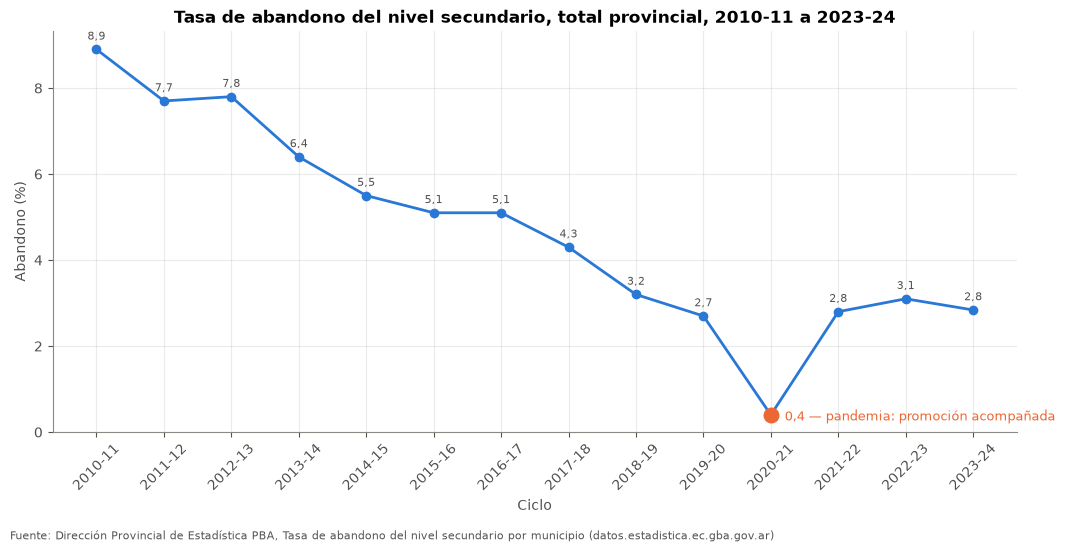

In [8]:
serie_provincial = df_total_provincia.set_index("periodo")["abandono_pct"].reindex(CICLOS)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(CICLOS, serie_provincial.to_numpy(), marker="o", color=u.PALETA[0])
ax.scatter([CICLO_ATIPICO], [serie_provincial[CICLO_ATIPICO]], s=110, color=u.PALETA[1], zorder=3)
ax.annotate(f"{serie_provincial[CICLO_ATIPICO]:.1f}".replace(".", ",") + " — pandemia: promoción acompañada", (CICLO_ATIPICO, serie_provincial[CICLO_ATIPICO]),
            xytext=(10, -4), textcoords="offset points", fontsize=9, color=u.PALETA[1])
for ciclo, valor in serie_provincial.drop(CICLO_ATIPICO).items():
    ax.annotate(f"{valor:.1f}".replace(".", ","), (ciclo, valor), xytext=(0, 7), textcoords="offset points",
                ha="center", fontsize=8, color=u.TEXTO_SECUNDARIO)
ax.set_title("Tasa de abandono del nivel secundario, total provincial, 2010-11 a 2023-24")
ax.set_xlabel("Ciclo")
ax.set_ylabel("Abandono (%)")
ax.set_ylim(bottom=0)
ax.tick_params(axis="x", rotation=45)
u.guardar_figura(fig, "04_abandono_provincial", FUENTE)
plt.show()

Variaciones entre ciclos, en puntos porcentuales (pp). Se reportan con y sin 2020-21: el tramo completo y los tramos antes y después de la pandemia.

In [9]:
TRAMOS = [
    ("Completo (con 2020-21 adentro)", "2010-11", "2023-24"),
    ("Antes de la pandemia (sin 2020-21)", "2010-11", "2019-20"),
    ("Después de la pandemia (sin 2020-21)", "2021-22", "2023-24"),
    ("Salto de la pandemia", "2019-20", "2020-21"),
    ("Rebote", "2020-21", "2021-22"),
    ("Tramo superpuesto con el 02", "2015-16", "2023-24"),
]
df_tramos_provincia = pd.DataFrame([
    {"tramo": nombre, "desde": a, "hasta": b, "valor_desde": serie_provincial[a], "valor_hasta": serie_provincial[b],
     "variacion_pp": serie_provincial[b] - serie_provincial[a]}
    for nombre, a, b in TRAMOS
]).round(2)
u.guardar_tabla(df_tramos_provincia, "04_tramos_provincia", index=False)
df_tramos_provincia

,tramo,desde,hasta,valor_desde,valor_hasta,variacion_pp
0,Completo (con 2020-21 adentro),2010-11,2023-24,8.9,2.84,-6.06
1,Antes de la pandemia (sin 2020-21),2010-11,2019-20,8.9,2.70,-6.20
2,Después de la pandemia (sin 2020-21),2021-22,2023-24,2.8,2.84,0.04
3,Salto de la pandemia,2019-20,2020-21,2.7,0.40,-2.30
4,Rebote,2020-21,2021-22,0.4,2.80,2.40
5,Tramo superpuesto con el 02,2015-16,2023-24,5.1,2.84,-2.26


<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-provincia -->
El abandono provincial baja de 8,9 % (2010-11) a 2,84 % (2023-24). **2020-21 es atípico (0,4 % provincial contra 2,7 % y 2,8 % en los ciclos vecinos); coincide con la pandemia y la promoción acompañada. Se reporta con y sin él.** La baja ocurre sobre todo antes de la pandemia (de 8,9 % a 2,7 % entre 2010-11 y 2019-20). Después, el nivel se mantiene: 2,8 % en 2021-22 y 2,84 % en 2023-24.

## 3. Municipios

Para cada municipio: el último ciclo (2023-24); la **mediana de los ciclos recientes 2021-22 a 2023-24** (principal: excluye 2020-21 y es robusta a negativos); el promedio de esos ciclos (secundario); y la mediana de 2020-21 a 2023-24 (sensibilidad).

In [10]:
pivot_abandono = df_abandono.pivot(index="municipio_nombre", columns="periodo", values="abandono_pct")[CICLOS]

df_municipio = pd.DataFrame({
    "region_educativa": df_abandono.drop_duplicates("municipio_nombre").set_index("municipio_nombre")["region_educativa"],
    "ultimo_2023_24": pivot_abandono["2023-24"],
    "mediana_reciente": pivot_abandono[CICLOS_RECIENTES].median(axis=1),
    "promedio_reciente": pivot_abandono[CICLOS_RECIENTES].mean(axis=1),
    "mediana_reciente_con_2020_21": pivot_abandono[CICLOS_RECIENTES_SENS].median(axis=1),
    "ciclos_negativos": (pivot_abandono < 0).sum(axis=1),
})
df_municipio["signo_ultimo"] = np.select(
    [df_municipio["ultimo_2023_24"] < 0, df_municipio["ultimo_2023_24"] == 0], ["negativo", "cero"], default="positivo"
)
df_municipio["cambio_pp_extremos"] = pivot_abandono["2023-24"] - pivot_abandono["2015-16"]
df_municipio["cambio_pp_robusto"] = df_municipio["mediana_reciente"] - pivot_abandono[CICLOS_BASE].median(axis=1)
assert len(df_municipio) == 135 and u.CODIGO_TOTAL_PROVINCIA not in set(df_abandono["cod_municipio"])
u.guardar_tabla(df_municipio.round(3), "04_municipios_abandono")

print("Mayor abandono (mediana 2021-22 a 2023-24)")
display(df_municipio.nlargest(15, "mediana_reciente").round(2))
print("Menor abandono (mediana 2021-22 a 2023-24)")
display(df_municipio.nsmallest(15, "mediana_reciente").round(2))

Mayor abandono (mediana 2021-22 a 2023-24)


,region_educativa,ultimo_2023_24,mediana_reciente,promedio_reciente,mediana_reciente_con_2020_21,ciclos_negativos,signo_ultimo,cambio_pp_extremos,cambio_pp_robusto
municipio_nombre,,,,,,,,,
Hipólito Yrigoyen,Región 15,6.26,6.26,6.59,5.68,0,positivo,-4.44,-4.44
Carlos Tejedor,Región 16,4.52,6.20,7.14,5.36,1,positivo,-3.78,-2.10
General Guido,Región 18,7.37,6.10,4.89,4.70,1,positivo,-1.03,-2.30
Tordillo,Región 18,7.03,6.10,5.18,5.00,2,positivo,3.43,2.50
Pellegrini,Región 16,8.89,6.00,4.63,2.50,3,positivo,5.89,3.00
Carlos Casares,Región 15,5.87,5.87,5.19,4.69,0,positivo,-0.83,-0.83
Lezama,Región 17,-1.90,5.10,3.33,2.45,2,negativo,-5.10,1.90
San Pedro,Región 12,5.38,5.00,4.99,4.80,0,positivo,-0.52,-0.90
Ayacucho,Región 18,4.91,4.91,3.14,4.16,1,positivo,0.11,0.11


Menor abandono (mediana 2021-22 a 2023-24)


,region_educativa,ultimo_2023_24,mediana_reciente,promedio_reciente,mediana_reciente_con_2020_21,ciclos_negativos,signo_ultimo,cambio_pp_extremos,cambio_pp_robusto
municipio_nombre,,,,,,,,,
Castelli,Región 18,3.90,-0.80,0.17,-1.70,4,positivo,-2.80,-7.50
Monte Hermoso,Región 22,3.91,-0.60,0.34,0.45,6,positivo,4.41,-0.10
Salliqueló,Región 16,-0.33,-0.33,0.06,0.68,3,negativo,-5.33,-5.33
Roque Pérez,Región 24,-0.15,-0.15,0.42,0.32,2,negativo,-9.75,-9.75
Navarro,Región 10,0.24,0.24,-1.22,0.27,2,positivo,-3.96,-3.96
General Paz,Región 17,2.04,0.40,0.55,1.22,2,positivo,0.24,-1.40
Pila,Región 17,1.52,0.50,0.51,0.60,4,positivo,2.82,1.80
Balcarce,Región 20,0.54,0.54,0.31,-0.13,3,positivo,-5.36,-5.36
Dolores,Región 18,3.87,1.00,1.72,1.20,0,positivo,0.47,-2.40


In [11]:
correlacion_sensibilidad = df_municipio[["mediana_reciente", "mediana_reciente_con_2020_21"]].corr(method="spearman").iloc[0, 1]
top15_en_comun = len(set(df_municipio["mediana_reciente"].nlargest(15).index)
                     & set(df_municipio["mediana_reciente_con_2020_21"].nlargest(15).index))
correlacion_mediana_promedio = df_municipio[["mediana_reciente", "promedio_reciente"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman mediana reciente vs. mediana con 2020-21: {correlacion_sensibilidad:.2f} | top 15 en común: {top15_en_comun}")
print(f"Spearman mediana reciente vs. promedio reciente: {correlacion_mediana_promedio:.2f}")
print("Municipios con 2023-24 negativo:", df_municipio.index[df_municipio["signo_ultimo"] == "negativo"].tolist())

Spearman mediana reciente vs. mediana con 2020-21: 0.87 | top 15 en común: 13
Spearman mediana reciente vs. promedio reciente: 0.89
Municipios con 2023-24 negativo: ['Lezama', 'Roque Pérez', 'Salliqueló']


<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-municipios -->
Los municipios con mayor abandono reciente son chicos y del interior: Hipólito Yrigoyen (mediana 6,26 %), Carlos Tejedor (6,20 %), General Guido y Tordillo (6,10 %). La mediana provincial de las medianas municipales es 2,9 %.
4 municipios tienen mediana reciente negativa (Castelli, Monte Hermoso, Salliqueló y Roque Pérez) y 3 tienen el último ciclo negativo (Lezama, Roque Pérez y Salliqueló). Los valores de los municipios chicos son volátiles: Lezama tiene mediana 5,10 %, pero −1,90 % en 2023-24.
El ranking es estable frente a las alternativas: Spearman 0,87 entre la mediana reciente y la mediana con 2020-21 (13 de los 15 primeros se repiten), y 0,89 entre la mediana y el promedio de los mismos ciclos.

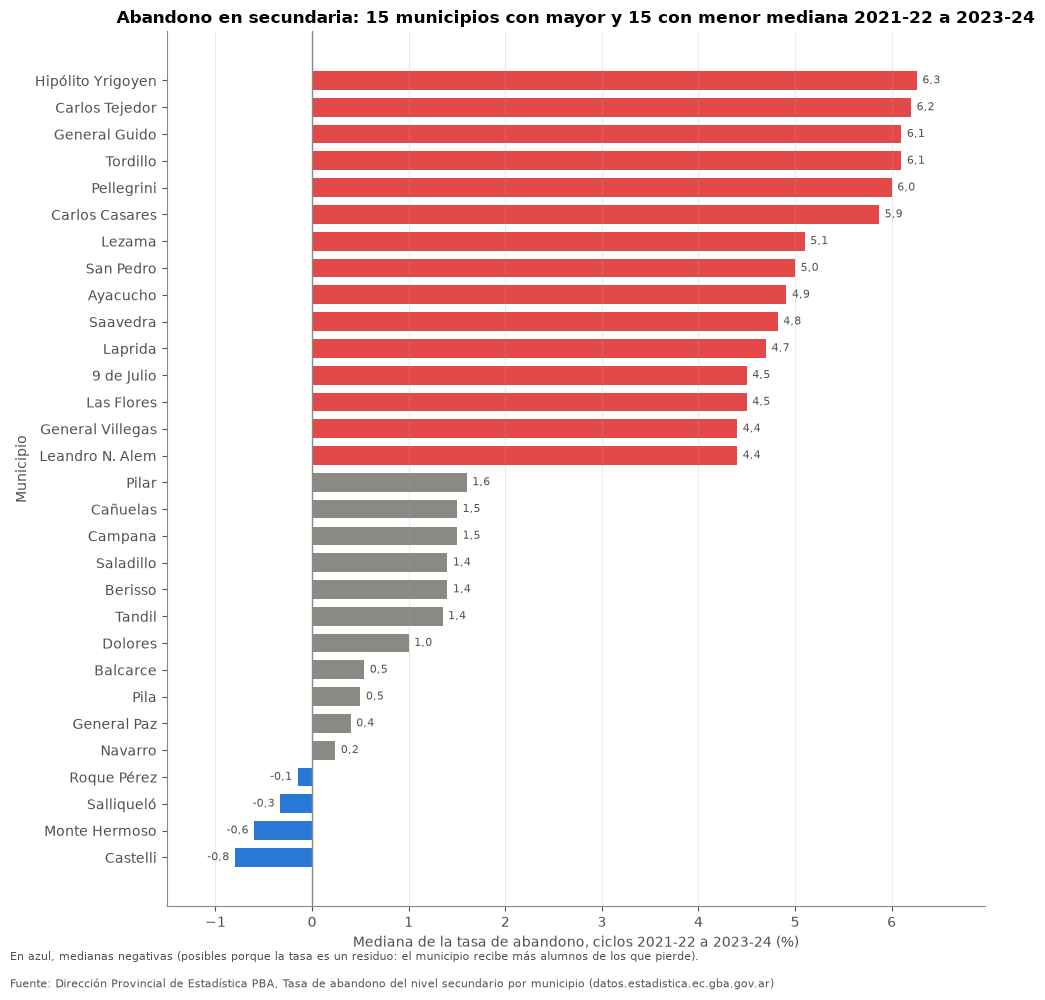

In [12]:
extremos = pd.concat([df_municipio.nsmallest(15, "mediana_reciente"), df_municipio.nlargest(15, "mediana_reciente").iloc[::-1]])
extremos = extremos.sort_values("mediana_reciente")

fig, ax = plt.subplots(figsize=(10, 10))
colores = [u.PALETA[0] if v < 0 else (u.PALETA[7] if v >= df_municipio["mediana_reciente"].median() else u.GRIS)
           for v in extremos["mediana_reciente"]]
ax.barh(extremos.index, extremos["mediana_reciente"], color=colores, height=0.7)
ax.axvline(0, color=u.GRIS, linewidth=1)
for y, v in enumerate(extremos["mediana_reciente"]):
    ax.annotate(f"{v:.1f}".replace(".", ","), (v, y), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                va="center", ha="left" if v >= 0 else "right", fontsize=8, color=u.TEXTO_SECUNDARIO)
ax.margins(x=0.1)
ax.set_title("Abandono en secundaria: 15 municipios con mayor y 15 con menor mediana 2021-22 a 2023-24")
ax.set_xlabel("Mediana de la tasa de abandono, ciclos 2021-22 a 2023-24 (%)")
ax.set_ylabel("Municipio")
ax.grid(axis="y", visible=False)
fig.text(0.01, 0.035, "En azul, medianas negativas (posibles porque la tasa es un residuo: el municipio recibe más alumnos de los que pierde).",
         fontsize=8, color=u.TEXTO_SECUNDARIO)
u.guardar_figura(fig, "04_municipios_extremos", FUENTE)
plt.show()

Cambio en el tramo superpuesto con el 02: el ciclo 2023-24 menos el 2015-16 (entre extremos) y, más robusto, la mediana 2021-22 a 2023-24 menos la mediana 2015-16 a 2017-18. En puntos porcentuales.

In [13]:
columnas_cambio = ["mediana_reciente", "cambio_pp_robusto", "cambio_pp_extremos"]
print("Mayores bajas (cambio robusto)")
display(df_municipio.nsmallest(10, "cambio_pp_robusto")[columnas_cambio].round(2))
print("Mayores subas (cambio robusto)")
display(df_municipio.nlargest(10, "cambio_pp_robusto")[columnas_cambio].round(2))
municipios_bajan = (df_municipio["cambio_pp_robusto"] < 0).sum()
print(f"Municipios que bajan (cambio robusto < 0): {municipios_bajan} de {len(df_municipio)}")

Mayores bajas (cambio robusto)


,mediana_reciente,cambio_pp_robusto,cambio_pp_extremos
municipio_nombre,,,
Roque Pérez,-0.15,-9.75,-9.75
Castelli,-0.80,-7.50,-2.80
Azul,2.10,-6.20,-6.98
Zárate,2.80,-5.80,-5.72
General Viamonte,2.90,-5.70,-6.22
Balcarce,0.54,-5.36,-5.36
Salliqueló,-0.33,-5.33,-5.33
Campana,1.50,-5.10,-4.06
Cañuelas,1.50,-5.10,-2.51


Mayores subas (cambio robusto)


,mediana_reciente,cambio_pp_robusto,cambio_pp_extremos
municipio_nombre,,,
General Alvear,1.73,8.63,8.63
Adolfo Alsina,2.70,6.80,6.19
San Cayetano,2.20,6.20,7.16
Lobería,2.20,4.60,4.28
Rojas,2.10,3.10,1.90
Pellegrini,6.00,3.00,5.89
Mar Chiquita,3.47,2.67,2.67
Punta Indio,1.90,2.60,2.17
Tordillo,6.10,2.50,3.43


Municipios que bajan (cambio robusto < 0): 112 de 135


<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-cambio -->
Entre el inicio del tramo superpuesto (mediana 2015-16 a 2017-18) y los ciclos recientes (mediana 2021-22 a 2023-24), el abandono baja en 112 de los 135 municipios; la mediana del cambio es −2,1 pp. Las mayores bajas son las de Roque Pérez (−9,75 pp) y Castelli (−7,50 pp); las mayores subas, las de General Alvear (+8,63 pp) y Adolfo Alsina (+6,80 pp).

Heatmap municipio × ciclo, con una escala divergente centrada en 0 para que los negativos (en azul) no se pierdan. Ordenado por la mediana reciente.

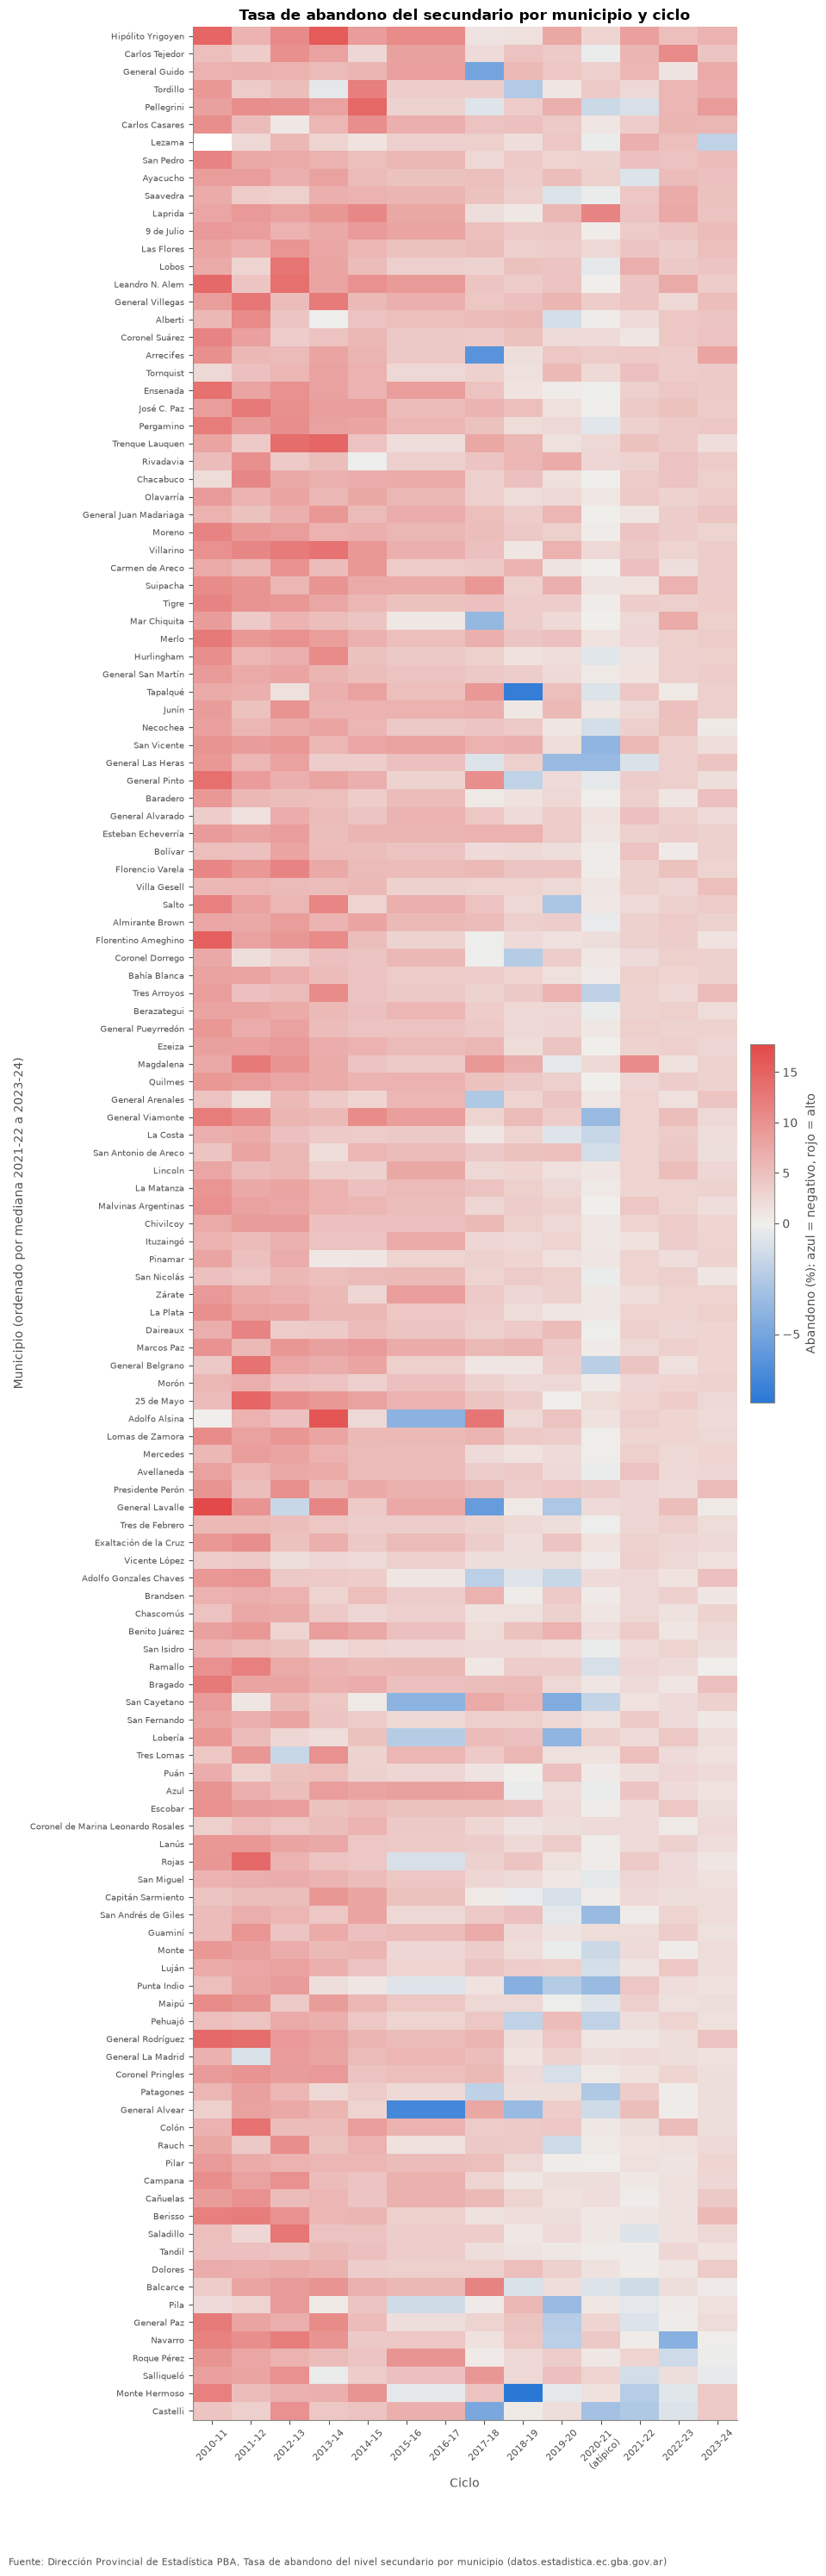

In [14]:
orden = df_municipio["mediana_reciente"].sort_values(ascending=False).index
datos_heatmap = pivot_abandono.loc[orden]
norma = TwoSlopeNorm(vmin=np.nanmin(datos_heatmap.to_numpy()), vcenter=0, vmax=np.nanmax(datos_heatmap.to_numpy()))

fig, ax = plt.subplots(figsize=(10, 30))
imagen = ax.imshow(datos_heatmap.to_numpy(), aspect="auto", cmap=u.CMAP_DIVERGENTE.reversed(), norm=norma,
                   interpolation="nearest")
ax.set_yticks(range(len(orden)), orden, fontsize=7)
ax.set_xticks(range(len(CICLOS)), [c + ("\n(atípico)" if c == CICLO_ATIPICO else "") for c in CICLOS], rotation=45, fontsize=8)
ax.grid(False)
barra = fig.colorbar(imagen, ax=ax, shrink=0.15, aspect=15, pad=0.02)
barra.set_label("Abandono (%): azul = negativo, rojo = alto")
ax.set_title("Tasa de abandono del secundario por municipio y ciclo")
ax.set_xlabel("Ciclo")
ax.set_ylabel("Municipio (ordenado por mediana 2021-22 a 2023-24)")
u.guardar_figura(fig, "04_heatmap_municipios", FUENTE)
plt.show()

## 4. Regiones

**Principal**: la mediana de los municipios de cada región. No pondera, pero es robusta a negativos y municipios chicos.
**Sensibilidad**: el promedio ponderado por la matrícula de Nivel Secundario del padrón 2026 (matrícula del sistema). Es una aproximación: esa matrícula no es la del ciclo 2023-24, que es el último del dataset.

In [15]:
es_secundario = df_padron_analisis["nivel"] == "Nivel Secundario"
matricula_secundaria = df_padron_analisis[es_secundario].groupby("municipio_nombre")["matricula_sistema"].sum()
df_municipio["matricula_secundaria_2026"] = matricula_secundaria
assert df_municipio["matricula_secundaria_2026"].notna().all()


def promedio_ponderado(grupo):
    return np.average(grupo["mediana_reciente"], weights=grupo["matricula_secundaria_2026"])


df_region = df_municipio.groupby("region_educativa").agg(
    municipios=("mediana_reciente", "size"),
    mediana_municipios=("mediana_reciente", "median"),
    matricula_secundaria_2026=("matricula_secundaria_2026", "sum"),
)
df_region["ponderado_matricula_2026"] = df_municipio.groupby("region_educativa").apply(promedio_ponderado, include_groups=False)
df_region["rank_mediana"] = df_region["mediana_municipios"].rank(ascending=False, method="min").astype(int)
df_region["rank_ponderado"] = df_region["ponderado_matricula_2026"].rank(ascending=False, method="min").astype(int)
df_region = df_region.sort_values("mediana_municipios", ascending=False)
assert df_region["municipios"].sum() == 135
u.guardar_tabla(df_region.round(3), "04_regiones_abandono")

correlacion_regiones = df_region[["mediana_municipios", "ponderado_matricula_2026"]].corr(method="spearman").iloc[0, 1]
top5_region_en_comun = len(set(df_region["mediana_municipios"].nlargest(5).index) & set(df_region["ponderado_matricula_2026"].nlargest(5).index))
print(f"Spearman entre mediana y ponderado: {correlacion_regiones:.2f} | top 5 en común: {top5_region_en_comun}")
display(df_region.round(2))

serie_regional = df_abandono.groupby(["region_educativa", "periodo"])["abandono_pct"].median().unstack()[CICLOS]
u.guardar_tabla(serie_regional.round(2), "04_regiones_serie_mediana");

Spearman entre mediana y ponderado: 0.82 | top 5 en común: 2


,municipios,mediana_municipios,matricula_secundaria_2026,ponderado_matricula_2026,rank_mediana,rank_ponderado
region_educativa,,,,,,
Región 15,7,4.30,25464,3.38,1,3
Región 16,7,3.90,13835,3.91,2,1
Región 7,3,3.30,82793,3.08,3,10
Región 9,4,3.25,180713,3.18,4,7
Región 25,4,3.20,24143,3.13,5,8
Región 19,3,3.20,70321,3.03,6,12
Región 14,8,3.15,26233,3.31,7,4
Región 5,5,3.10,146103,3.06,8,11
Región 12,6,3.00,38344,3.29,9,5


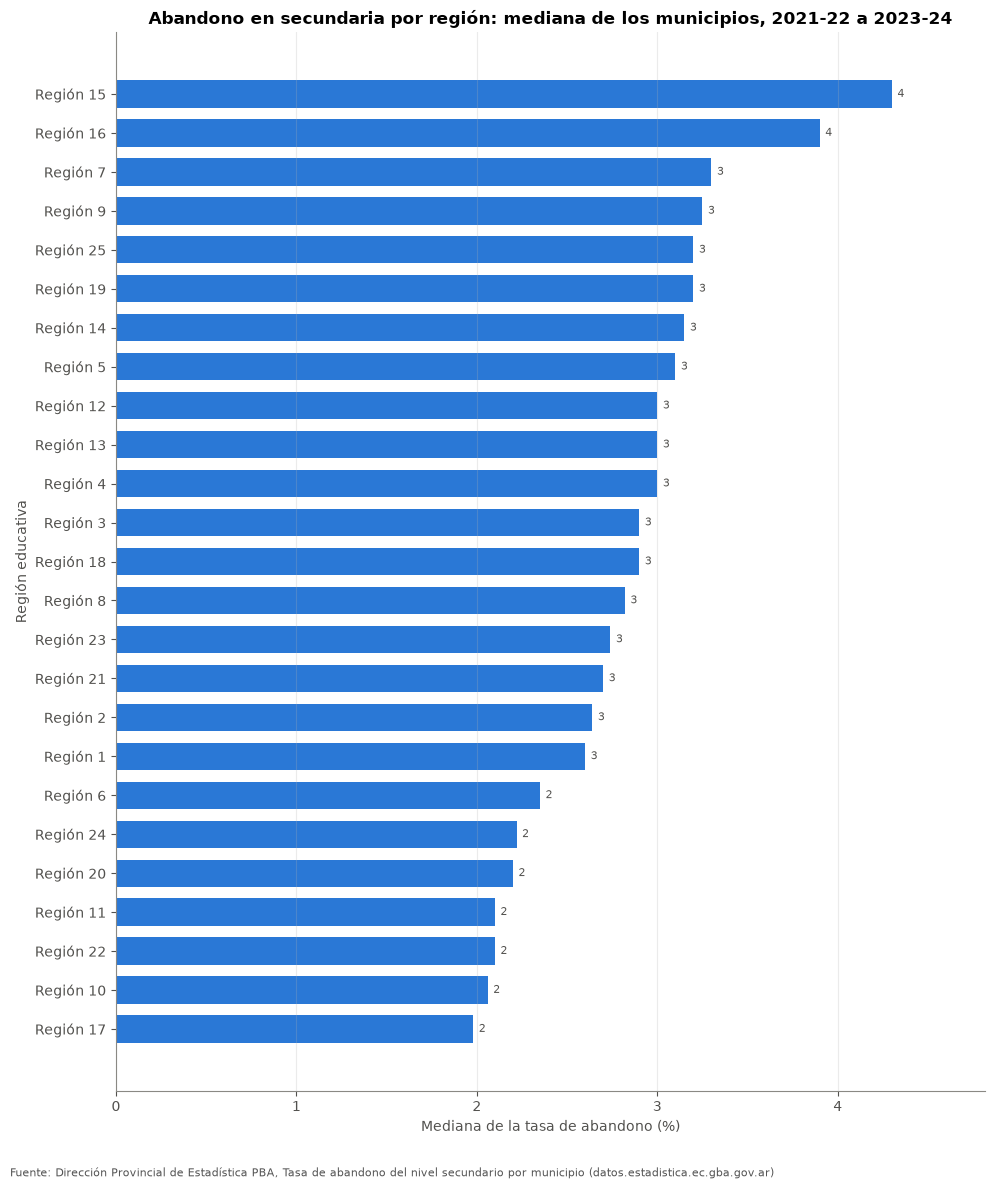

In [16]:
u.grafico_barras_h(df_region["mediana_municipios"].round(2), "Abandono en secundaria por región: mediana de los municipios, 2021-22 a 2023-24",
                   "Mediana de la tasa de abandono (%)", "Región educativa", "04_regiones_abandono", FUENTE)
plt.show()

<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-regiones -->
Las dos agregaciones dan rankings parecidos en general (Spearman 0,82), pero **difieren en los primeros puestos**: solo 2 regiones se repiten en los dos top 5. Por eso se muestran lado a lado (tabla de arriba y gráfico siguiente). Con la mediana encabezan las Regiones 15 (4,30 %) y 16 (3,90 %); con el ponderado, la 16 (3,91 %) y la 23 (3,40 %). Las diferencias entre regiones son chicas: las medianas van de 1,98 % a 4,30 %. Conviene no sacar conclusiones regionales fuertes de un solo ranking.

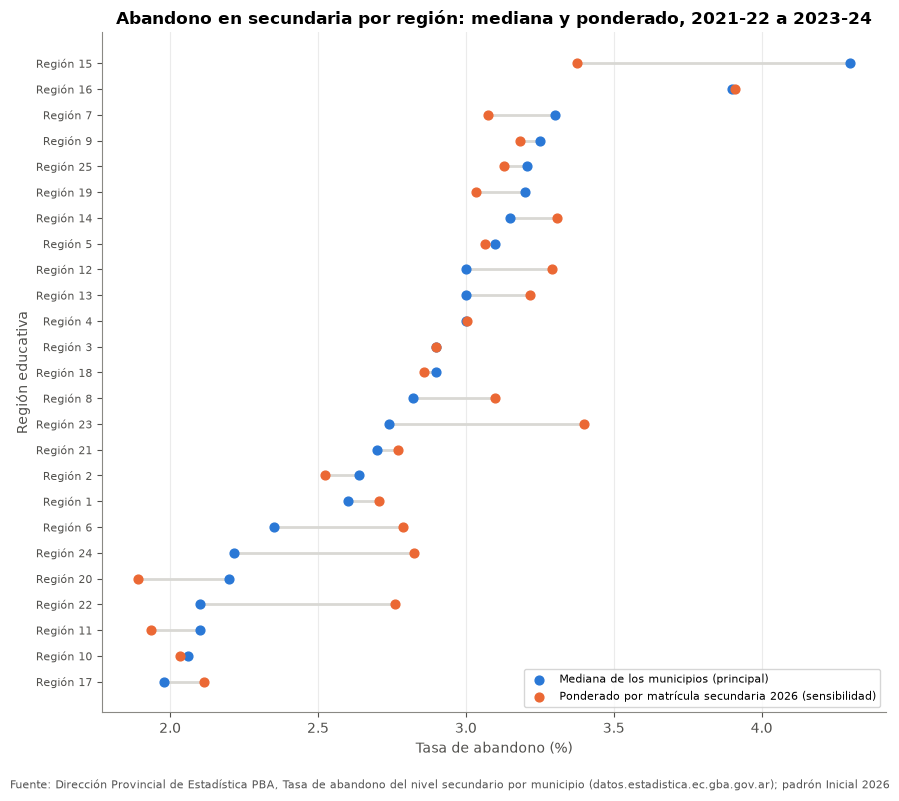

In [17]:
comparacion_regiones = df_region.sort_values("mediana_municipios")
fig, ax = plt.subplots(figsize=(9, 8))
posiciones = np.arange(len(comparacion_regiones))
extremos_region = comparacion_regiones[["mediana_municipios", "ponderado_matricula_2026"]]
ax.hlines(posiciones, extremos_region.min(axis=1), extremos_region.max(axis=1), color="#d9d8d4", linewidth=2)
ax.scatter(comparacion_regiones["mediana_municipios"], posiciones, color=u.PALETA[0], s=40, zorder=3,
           label="Mediana de los municipios (principal)")
ax.scatter(comparacion_regiones["ponderado_matricula_2026"], posiciones, color=u.PALETA[1], s=40, zorder=3,
           label="Ponderado por matrícula secundaria 2026 (sensibilidad)")
ax.set_yticks(posiciones, comparacion_regiones.index, fontsize=8)
ax.set_title("Abandono en secundaria por región: mediana y ponderado, 2021-22 a 2023-24")
ax.set_xlabel("Tasa de abandono (%)")
ax.set_ylabel("Región educativa")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=8)
u.guardar_figura(fig, "04_regiones_mediana_vs_ponderado", FUENTE_CRUCE_01)
plt.show()

## 5. Cruce con la serie de matrícula (notebook 02)

<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-superposicion-02 -->
La superposición con la serie 2015–2025 del 02 es de 9 ciclos (2015-16 a 2023-24), no de 10; el ciclo 2024-25 no está en el dataset. Se compara el cambio de abandono con la variación de matrícula entre los mismos años base (2015 y 2023). **Salvedad**: la tasa es solo del nivel secundario y la matrícula del 02 suma todos los niveles.

In [18]:
df_serie = u.cargar_matricula_municipios()
serie_pivot = df_serie.pivot(index="municipio_nombre", columns="anio", values="matricula")
variacion_matricula = ((serie_pivot[2023] / serie_pivot[2015] - 1) * 100).rename("variacion_matricula_2015_2023_pct")

sin_par = set(df_municipio.index) ^ set(variacion_matricula.index)
print("Municipios sin par entre abandono y serie (después de normalizar):", sorted(sin_par) or "ninguno")

df_cruce_02 = df_municipio.join(variacion_matricula, validate="one_to_one")
df_correlaciones_02 = pd.Series({
    "cambio robusto vs. variación de matrícula 2015→2023":
        df_cruce_02[["cambio_pp_robusto", "variacion_matricula_2015_2023_pct"]].corr(method="spearman").iloc[0, 1],
    "cambio entre extremos vs. variación de matrícula 2015→2023":
        df_cruce_02[["cambio_pp_extremos", "variacion_matricula_2015_2023_pct"]].corr(method="spearman").iloc[0, 1],
}, name="spearman").round(3)
u.guardar_tabla(df_cruce_02.round(3), "04_cruce_serie_02")
u.guardar_tabla(df_correlaciones_02.to_frame(), "04_correlaciones_02")
df_correlaciones_02.to_frame()

Municipios sin par entre abandono y serie (después de normalizar): ninguno


,spearman
cambio robusto vs. variación de matrícula 2015→2023,-0.013
cambio entre extremos vs. variación de matrícula 2015→2023,0.087


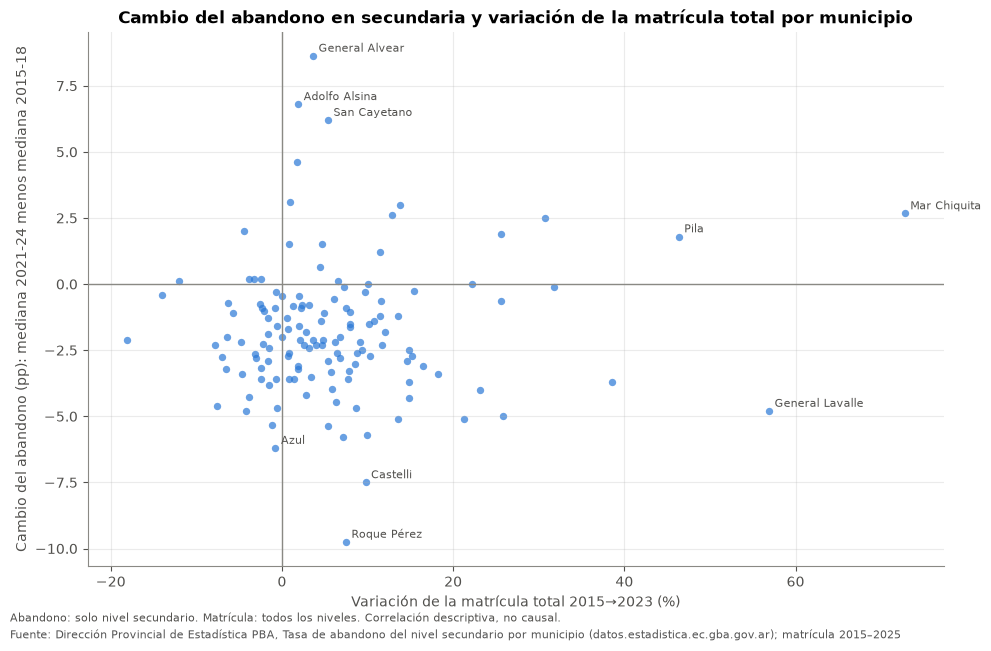

In [19]:
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.scatter(df_cruce_02["variacion_matricula_2015_2023_pct"], df_cruce_02["cambio_pp_robusto"], s=28, alpha=0.7,
           color=u.PALETA[0], linewidths=0)
ax.axhline(0, color=u.GRIS, linewidth=1)
ax.axvline(0, color=u.GRIS, linewidth=1)
for municipio in set(df_cruce_02["cambio_pp_robusto"].nlargest(3).index) | set(df_cruce_02["cambio_pp_robusto"].nsmallest(3).index) \
        | set(df_cruce_02["variacion_matricula_2015_2023_pct"].nlargest(3).index):
    fila = df_cruce_02.loc[municipio]
    ax.annotate(municipio, (fila["variacion_matricula_2015_2023_pct"], fila["cambio_pp_robusto"]),
                xytext=(4, 3), textcoords="offset points", fontsize=8, color=u.TEXTO_SECUNDARIO)
ax.set_title("Cambio del abandono en secundaria y variación de la matrícula total por municipio")
ax.set_xlabel("Variación de la matrícula total 2015→2023 (%)")
ax.set_ylabel("Cambio del abandono (pp): mediana 2021-24 menos mediana 2015-18")
fig.text(0.01, 0.035, "Abandono: solo nivel secundario. Matrícula: todos los niveles. Correlación descriptiva, no causal.",
         fontsize=8, color=u.TEXTO_SECUNDARIO)
u.guardar_figura(fig, "04_cruce_matricula", FUENTE_CRUCE_02)
plt.show()

<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-cruce-02 -->
No hay asociación entre el cambio del abandono y la variación de la matrícula 2015→2023 (Spearman −0,01 con el cambio robusto y 0,09 con el cambio entre extremos). La baja del abandono ocurrió tanto en municipios que ganaron matrícula como en los que la perdieron. Es una comparación descriptiva, no causal.

## 6. Cruce con la expansión (notebook 03)

<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-superposicion-03 -->
El cruce con la expansión usa los ciclos 2020-21 a 2023-24 (4 ciclos), que es el tramo en que las dos fuentes se superponen. Los eventos del 03 son de 2020 a 2026, pero los ciclos del dataset de abandono terminan en 2023-24; no hay superposición con 2024-25 ni 2025-26. Por eso se toman solo los eventos de **nivel secundario** (escuelas secundarias, técnicas, agrarias y CENS) con acto entre 2020 y 2023. Se compara el **nivel** de abandono en esos 4 ciclos (mediana 2020-21 a 2023-24), no su cambio: el cambio desde 2020-21 estaría distorsionado por el ciclo atípico.

In [20]:
df_expansion = u.cargar_expansion()
es_evento_secundario = df_expansion["tipo_organizacion"].str.contains("SECUNDARIA|C.E.N.S.", regex=True, na=False)
eventos_secundarios = df_expansion[es_evento_secundario & df_expansion["fecha_acto"].dt.year.between(2020, 2023)]
print("Eventos de nivel secundario 2020–2023:", len(eventos_secundarios), "de", len(df_expansion), "eventos totales")
print(eventos_secundarios["tipo_organizacion"].value_counts().to_dict())

df_cruce_03 = df_municipio[["mediana_reciente_con_2020_21", "matricula_secundaria_2026"]].copy()
df_cruce_03["eventos_secundarios"] = (
    eventos_secundarios["municipio_id"].map(nombre_canonico).value_counts().reindex(df_cruce_03.index, fill_value=0)
)
df_cruce_03["eventos_sec_10k"] = df_cruce_03["eventos_secundarios"] / df_cruce_03["matricula_secundaria_2026"] * 10_000
con_eventos_sec = df_cruce_03[df_cruce_03["eventos_secundarios"] > 0]
sin_eventos_sec = df_cruce_03[df_cruce_03["eventos_secundarios"] == 0]

correlacion_03 = con_eventos_sec[["eventos_sec_10k", "mediana_reciente_con_2020_21"]].corr(method="spearman").iloc[0, 1]
df_grupos_03 = pd.DataFrame({
    "municipios": [len(con_eventos_sec), len(sin_eventos_sec)],
    "mediana_abandono_2020_24": [con_eventos_sec["mediana_reciente_con_2020_21"].median(), sin_eventos_sec["mediana_reciente_con_2020_21"].median()],
}, index=["con eventos secundarios", "sin eventos secundarios"]).round(2)
u.guardar_tabla(df_cruce_03.round(3), "04_cruce_expansion_03")
u.guardar_tabla(df_grupos_03, "04_grupos_expansion_03")
display(df_grupos_03)
print(f"Spearman entre eventos secundarios cada 10.000 alumnos de secundaria y abandono 2020-21 a 2023-24 "
      f"({len(con_eventos_sec)} municipios con eventos): {correlacion_03:.3f}")

Eventos de nivel secundario 2020–2023: 111 de 519 eventos totales
{'ESCUELA DE EDUCACIÓN SECUNDARIA': 72, 'CENTRO EDUCATIVO DE NIVEL SECUNDARIO (C.E.N.S.)': 32, 'ESCUELA DE EDUCACIÓN SECUNDARIA TÉCNICA': 5, 'ESCUELA DE EDUCACIÓN SECUNDARIA AGRARIA': 2}


,municipios,mediana_abandono_2020_24
con eventos secundarios,63,2.56
sin eventos secundarios,72,2.28


Spearman entre eventos secundarios cada 10.000 alumnos de secundaria y abandono 2020-21 a 2023-24 (63 municipios con eventos): 0.094


<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-cruce-03 -->
Entre 2020 y 2023 hubo 111 eventos de expansión de nivel secundario, en 63 municipios. Los municipios con esos eventos tienen una mediana de abandono 2020-21 a 2023-24 algo mayor (2,56 %) que los municipios sin ellos (2,28 %), y entre los 63 la intensidad de la expansión secundaria no se asocia con el abandono (Spearman 0,09). La expansión secundaria no aparece vinculada al nivel de abandono en estos datos; es descriptivo, no causal.

## 7. Cruce con el padrón (notebook 01)

<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-cruce-01-alcance -->
No hay superposición temporal entre el abandono 2023-24 y el padrón 2026; el cruce es estructural (tamaño del secundario, proporción rural, etc.) y debe leerse como asociación, no como relación temporal. Se usa la mediana 2021-22 a 2023-24 y la matrícula de Nivel Secundario del padrón (matrícula del sistema).

In [21]:
secundario = df_padron_analisis[es_secundario]
matricula_privada = secundario[secundario["sector"] == "Privado"].groupby("municipio_nombre")["matricula_sistema"].sum()
matricula_rural = secundario[secundario["ambito"].str.startswith("Rural", na=False)].groupby("municipio_nombre")["matricula_sistema"].sum()

df_cruce_01 = df_municipio[["mediana_reciente", "matricula_secundaria_2026"]].copy()
df_cruce_01["pct_privado_secundario"] = (matricula_privada.reindex(df_cruce_01.index, fill_value=0) / df_cruce_01["matricula_secundaria_2026"] * 100)
df_cruce_01["pct_rural_secundario"] = (matricula_rural.reindex(df_cruce_01.index, fill_value=0) / df_cruce_01["matricula_secundaria_2026"] * 100)

df_correlaciones_01 = pd.Series({
    variable: df_cruce_01[["mediana_reciente", variable]].corr(method="spearman").iloc[0, 1]
    for variable in ["matricula_secundaria_2026", "pct_privado_secundario", "pct_rural_secundario"]
}, name="spearman_con_mediana_reciente").round(3)
u.guardar_tabla(df_cruce_01.round(3), "04_cruce_padron_01")
u.guardar_tabla(df_correlaciones_01.to_frame(), "04_correlaciones_01")
df_correlaciones_01.to_frame()

,spearman_con_mediana_reciente
matricula_secundaria_2026,-0.006
pct_privado_secundario,-0.038
pct_rural_secundario,0.021


<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-cruce-01 -->
Ninguna de las tres características estructurales se asocia con el abandono reciente: tamaño del secundario (Spearman −0,01), proporción de matrícula secundaria privada (−0,04) y proporción rural (0,02). Las diferencias de abandono entre municipios no se explican por estas variables del padrón.

<!-- verificado 2026-10-21, hash datos: aband=5afbfea;padron=d62f13c;serie=62c8e36;exp=c3cc336, id: md-casos -->
## 8. Casos candidatos para el informe de síntesis (05)

Solo se identifican; se redactan en el 05.
1. **El abandono provincial bajó de 8,9 % a 2,84 %** entre 2010-11 y 2023-24, sobre todo antes de la pandemia; después se mantiene cerca de 2,8 %.
2. **La baja es generalizada**: 112 de 135 municipios bajan su abandono entre 2015-18 y 2021-24. Hay excepciones con subas fuertes (General Alvear, +8,63 pp).
3. **El abandono reciente más alto está en municipios chicos del interior** (Hipólito Yrigoyen, Carlos Tejedor), con valores volátiles entre ciclos.
4. **El abandono no se asocia con las otras dimensiones del informe**: ni con la variación de matrícula (02), ni con la expansión secundaria (03), ni con la estructura del padrón (01); todas las correlaciones están por debajo de 0,1 en valor absoluto.
5. **2020-21 es atípico** (0,4 % provincial, pandemia y promoción acompañada): cualquier serie que lo incluya tiene que marcarlo.
6. **La vista regional depende del método**: mediana y ponderado coinciden solo en 2 de los 5 primeros puestos.

## Cifras para el informe de síntesis

Deja en `outputs/04_cifras_informe.csv` las cifras que usa el informe de síntesis (05). No es análisis nuevo: son valores ya calculados en este notebook.

In [22]:
correlacion_max_abs = max(df_correlaciones_02.abs().max(), abs(correlacion_03), df_correlaciones_01.abs().max())
df_cifras_informe = u.guardar_cifras_informe([
    ("abandono_2010_11", serie_provincial["2010-11"], "%", "celda 20", "Abandono secundario, total provincial, ciclo 2010-11"),
    ("abandono_2019_20", serie_provincial["2019-20"], "%", "celda 20", "Abandono secundario, total provincial, ciclo 2019-20"),
    ("abandono_2020_21", serie_provincial["2020-21"], "%", "celda 20", "Ciclo atípico: pandemia y promoción acompañada"),
    ("abandono_2021_22", serie_provincial["2021-22"], "%", "celda 20", "Abandono secundario, total provincial, ciclo 2021-22"),
    ("abandono_2023_24", serie_provincial["2023-24"], "%", "celda 20", "Abandono secundario, total provincial, ciclo 2023-24 (último)"),
    ("municipios_bajan_abandono", municipios_bajan, "municipios", "celda 30", "Municipios con cambio robusto < 0 (mediana 2021-24 menos mediana 2015-18), de 135"),
    ("mediana_cambio_abandono", df_municipio["cambio_pp_robusto"].median(), "pp", "celda 25", "Mediana del cambio robusto del abandono por municipio"),
    ("valores_negativos", len(negativos), "valores", "celda 15", "Valores municipales negativos (la tasa es un residuo)"),
    ("valores_negativos_pct", pct_negativos, "%", "celda 15", "Negativos sobre los 1.889 valores municipales con dato"),
    ("eventos_secundarios_2020_2023", len(eventos_secundarios), "eventos", "celda 46", "Eventos de expansión de nivel secundario con acto 2020–2023"),
    ("municipios_con_eventos_secundarios", len(con_eventos_sec), "municipios", "celda 46", "Municipios con al menos un evento secundario 2020–2023"),
    ("spearman_expansion_abandono", correlacion_03, "Spearman", "celda 46", "Eventos secundarios cada 10.000 alumnos de secundaria vs. abandono 2020-21 a 2023-24 (63 municipios)"),
    ("abandono_con_eventos_secundarios", df_grupos_03.loc["con eventos secundarios", "mediana_abandono_2020_24"], "%", "celda 46", "Mediana de abandono 2020-21 a 2023-24 en municipios con eventos secundarios"),
    ("abandono_sin_eventos_secundarios", df_grupos_03.loc["sin eventos secundarios", "mediana_abandono_2020_24"], "%", "celda 46", "Ídem, municipios sin eventos secundarios"),
    ("correlacion_max_abs_cruces", correlacion_max_abs, "Spearman", "celda 50", "Mayor correlación en valor absoluto de los cruces con 02, 03 y 01"),
], "04")
df_cifras_informe

,cifra_id,valor,unidad,notebook,celda_origen,descripcion
0,abandono_2010_11,8.9000,%,04,celda 20,"Abandono secundario, total provincial, ciclo 2..."
1,abandono_2019_20,2.7000,%,04,celda 20,"Abandono secundario, total provincial, ciclo 2..."
2,abandono_2020_21,0.4000,%,04,celda 20,Ciclo atípico: pandemia y promoción acompañada
3,abandono_2021_22,2.8000,%,04,celda 20,"Abandono secundario, total provincial, ciclo 2..."
4,abandono_2023_24,2.8400,%,04,celda 20,"Abandono secundario, total provincial, ciclo 2..."
5,municipios_bajan_abandono,112.0000,municipios,04,celda 30,Municipios con cambio robusto < 0 (mediana 202...
6,mediana_cambio_abandono,-2.1000,pp,04,celda 25,Mediana del cambio robusto del abandono por mu...
7,valores_negativos,124.0000,valores,04,celda 15,Valores municipales negativos (la tasa es un r...
8,valores_negativos_pct,6.5643,%,04,celda 15,Negativos sobre los 1.889 valores municipales ...
9,eventos_secundarios_2020_2023,111.0000,eventos,04,celda 46,Eventos de expansión de nivel secundario con a...


## 9. Control de cifras citadas en los markdown

Igual que en el 01, 02 y 03: compara las cifras y listas escritas en los markdown marcados con el cálculo. No corrige textos. Con `MODO_ESTRICTO = False` solo reporta. La marca lleva el hash de cada uno de los cuatro archivos.

In [23]:
prov = serie_provincial
citas = [
    # Alcance y calidad
    ("md-alcance", "con 14 ciclos", len(CICLOS)),
    ("md-alcance", "para 135 municipios", df_abandono["municipio_id"].nunique()),
    ("md-nombres", "(código 182)", set(df_nombres_distintos["municipio_id"].str.slice(2).astype(int))),
    ("md-nombres", '"CORONEL DE MARINA L. ROSALES"', set(df_nombres_distintos["municipio_nombre_original"])),
    ("md-nulos", "Hay 1 nulo", len(df_nulos)),
    ("md-nulos", "Lezama no tiene dato en 2010-11", set(df_nulos["municipio_nombre"])),
    ("md-negativos", "(124 casos", len(negativos)),
    ("md-negativos", "6,6 % de los valores", pct_negativos),
    ("md-negativos", "2020-21 (39", negativos_por_ciclo["2020-21"]),
    ("md-negativos", "2019-20 (21", negativos_por_ciclo["2019-20"]),
    ("md-negativos", "Monte Hermoso tiene 6", negativos_por_municipio.get("Monte Hermoso", 0)),
    ("md-negativos", "(Monte Hermoso", {negativos_por_municipio.idxmax()}),
    ("md-precision", "2023-24 viene con 2 decimales", decimales["2023-24"]),
    ("md-precision", "anteriores con 1", decimales.drop("2023-24").max()),
    # Provincia
    ("md-provincia", "baja de 8,9 %", prov["2010-11"]),
    ("md-provincia", "a 2,84 %", prov["2023-24"]),
    ("md-provincia", "(0,4 % provincial", prov["2020-21"]),
    ("md-provincia", "contra 2,7 %", prov["2019-20"]),
    ("md-provincia", "y 2,8 % en los ciclos vecinos", prov["2021-22"]),
    ("md-provincia", "(de 8,9 %", prov["2010-11"]),
    ("md-provincia", "a 2,7 % entre", prov["2019-20"]),
    ("md-provincia", "el nivel se mantiene: 2,8 %", prov["2021-22"]),
    ("md-provincia", "y 2,84 % en", prov["2023-24"]),
    # Superposiciones
    ("md-superposicion-02", "es de 9 ciclos", len([c for c in CICLOS if 2015 <= int(c[:4]) <= 2025])),
    ("md-superposicion-03", "(4 ciclos)", len(CICLOS_RECIENTES_SENS)),
    # Textos interpretativos
    ("md-municipios", "Hipólito Yrigoyen (mediana 6,26 %)", df_municipio.loc["Hipólito Yrigoyen", "mediana_reciente"]),
    ("md-municipios", "Carlos Tejedor (6,20 %)", df_municipio.loc["Carlos Tejedor", "mediana_reciente"]),
    ("md-municipios", "General Guido y Tordillo (6,10 %)", df_municipio.loc["General Guido", "mediana_reciente"]),
    ("md-municipios", "Hipólito Yrigoyen (mediana 6,26 %), Carlos Tejedor (6,20 %), General Guido y Tordillo",
     set(df_municipio["mediana_reciente"].nlargest(4).index)),
    ("md-municipios", "medianas municipales es 2,9 %", df_municipio["mediana_reciente"].median()),
    ("md-municipios", "4 municipios tienen mediana reciente negativa", (df_municipio["mediana_reciente"] < 0).sum()),
    ("md-municipios", "(Castelli, Monte Hermoso, Salliqueló y Roque Pérez)", set(df_municipio.index[df_municipio["mediana_reciente"] < 0])),
    ("md-municipios", "y 3 tienen el último ciclo negativo", (df_municipio["signo_ultimo"] == "negativo").sum()),
    ("md-municipios", "(Lezama, Roque Pérez y Salliqueló)", set(df_municipio.index[df_municipio["signo_ultimo"] == "negativo"])),
    ("md-municipios", "Lezama tiene mediana 5,10 %", df_municipio.loc["Lezama", "mediana_reciente"]),
    ("md-municipios", "pero −1,90 %", df_municipio.loc["Lezama", "ultimo_2023_24"]),
    ("md-municipios", "Spearman 0,87", correlacion_sensibilidad),
    ("md-municipios", "(13", top15_en_comun),
    ("md-municipios", "y 0,89", correlacion_mediana_promedio),
    ("md-cambio", "baja en 112", municipios_bajan),
    ("md-cambio", "de los 135 municipios", len(df_municipio)),
    ("md-cambio", "mediana del cambio es −2,1 pp", df_municipio["cambio_pp_robusto"].median()),
    ("md-cambio", "Roque Pérez (−9,75 pp)", df_municipio.loc["Roque Pérez", "cambio_pp_robusto"]),
    ("md-cambio", "Castelli (−7,50 pp)", df_municipio.loc["Castelli", "cambio_pp_robusto"]),
    ("md-cambio", "Roque Pérez (−9,75 pp) y Castelli", set(df_municipio["cambio_pp_robusto"].nsmallest(2).index)),
    ("md-cambio", "General Alvear (+8,63 pp)", df_municipio.loc["General Alvear", "cambio_pp_robusto"]),
    ("md-cambio", "Adolfo Alsina (+6,80 pp)", df_municipio.loc["Adolfo Alsina", "cambio_pp_robusto"]),
    ("md-cambio", "General Alvear (+8,63 pp) y Adolfo Alsina", set(df_municipio["cambio_pp_robusto"].nlargest(2).index)),
    ("md-regiones", "(Spearman 0,82)", correlacion_regiones),
    ("md-regiones", "solo 2 regiones", top5_region_en_comun),
    ("md-regiones", "Regiones 15 (4,30 %)", df_region.loc["Región 15", "mediana_municipios"]),
    ("md-regiones", "y 16 (3,90 %)", df_region.loc["Región 16", "mediana_municipios"]),
    ("md-regiones", "la 16 (3,91 %)", df_region.loc["Región 16", "ponderado_matricula_2026"]),
    ("md-regiones", "y la 23 (3,40 %)", df_region.loc["Región 23", "ponderado_matricula_2026"]),
    ("md-regiones", "encabezan las Regiones 15 (4,30 %) y 16",
     set(df_region["mediana_municipios"].nlargest(2).index.str.extract(r"(\d+)", expand=False).astype(int))),
    ("md-regiones", "la 16 (3,91 %) y la 23",
     set(df_region["ponderado_matricula_2026"].nlargest(2).index.str.extract(r"(\d+)", expand=False).astype(int))),
    ("md-regiones", "van de 1,98 %", df_region["mediana_municipios"].min()),
    ("md-regiones", "a 4,30 %", df_region["mediana_municipios"].max()),
    ("md-cruce-02", "(Spearman −0,01", df_correlaciones_02.iloc[0]),
    ("md-cruce-02", "y 0,09 con el cambio entre extremos", df_correlaciones_02.iloc[1]),
    ("md-cruce-03", "hubo 111 eventos", len(eventos_secundarios)),
    ("md-cruce-03", "en 63 municipios", len(con_eventos_sec)),
    ("md-cruce-03", "algo mayor (2,56 %)", df_grupos_03.loc["con eventos secundarios", "mediana_abandono_2020_24"]),
    ("md-cruce-03", "sin ellos (2,28 %)", df_grupos_03.loc["sin eventos secundarios", "mediana_abandono_2020_24"]),
    ("md-cruce-03", "entre los 63", len(con_eventos_sec)),
    ("md-cruce-03", "(Spearman 0,09)", correlacion_03),
    ("md-cruce-01", "secundario (Spearman −0,01)", df_correlaciones_01["matricula_secundaria_2026"]),
    ("md-cruce-01", "privada (−0,04)", df_correlaciones_01["pct_privado_secundario"]),
    ("md-cruce-01", "rural (0,02)", df_correlaciones_01["pct_rural_secundario"]),
    ("md-casos", "bajó de 8,9 %", prov["2010-11"]),
    ("md-casos", "a 2,84 %", prov["2023-24"]),
    ("md-casos", "cerca de 2,8 %", prov["2021-22"]),
    ("md-casos", "generalizada**: 112", municipios_bajan),
    ("md-casos", "(General Alvear, +8,63 pp)", df_municipio.loc["General Alvear", "cambio_pp_robusto"]),
    ("md-casos", "(Hipólito Yrigoyen, Carlos Tejedor)", set(df_municipio["mediana_reciente"].nlargest(2).index)),
    ("md-casos", "por debajo de 0,1", round(max(df_correlaciones_02.abs().max(), abs(correlacion_03), df_correlaciones_01.abs().max()), 1)),
    ("md-casos", "(0,4 % provincial", prov["2020-21"]),
    ("md-casos", "solo en 2", top5_region_en_comun),
]

df_control_citas = u.verificar_citas(
    u.NOTEBOOKS_DIR / "04_abandono_secundario.ipynb", citas, HASH_DATOS, estricto=MODO_ESTRICTO,
    guardar_como="04_control_citas",
)
print(df_control_citas["estado"].value_counts().to_string())
with pd.option_context("display.max_rows", None):
    display(df_control_citas)

estado
OK    78


,markdown,celda,texto_citado,valor_citado,valor_calculado,estado
0,md-alcance,1,con 14 ciclos,14.0,14.0,OK
1,md-alcance,1,para 135 municipios,135.0,135.0,OK
2,md-nombres,10,(código 182),[182],[182],OK
3,md-nombres,10,"""CORONEL DE MARINA L. ROSALES""",lista de nombres,['CORONEL DE MARINA L. ROSALES'],OK
4,md-nulos,13,Hay 1 nulo,1.0,1.0,OK
5,md-nulos,13,Lezama no tiene dato en 2010-11,lista de nombres,['Lezama'],OK
6,md-negativos,16,(124 casos,124.0,124.0,OK
7,md-negativos,16,"6,6 % de los valores",6.6,6.56,OK
8,md-negativos,16,2020-21 (39,39.0,39.0,OK
9,md-negativos,16,2019-20 (21,21.0,21.0,OK
